# DMA 공간분석 PoC: Python 재현·검증 노트북

R(`spdep`·`spatialreg`)로 수행한 국가·지역 공간분석을 **저장된 CSV와 numpy/scipy만으로 독립 재계산**하는 노트북입니다.
전처리 → 공간가중치 W → Moran's I → VIF → OLS/SAR/SEM/SDM 최대우도 추정 → 효과 분해 → 부트스트랩 잔차 검정 → 민감도 → 2026-11-02 메커니즘 자료 순서로 진행하며, 각 단계에서 `outputs/`의 R 결과와 수치를 대조합니다.

- **새로 추정하거나 바꾸는 결과는 없습니다.** 모든 입력은 저장소의 `outputs/*.csv`이며 파일을 쓰지 않습니다.
- 재계산 코드는 `code/03_models.R`의 `make_weights`·`moran_value`·`vif_values`·`fast_fit`·`impact_values`를 Python으로 옮긴 것입니다. 수식과 선택(k=4 대칭 kNN, 행 표준화, ρ 탐색 구간 ±0.999, 집중 로그우도)을 동일하게 둡니다.
- 순열·부트스트랩은 난수열이 R과 다르므로 **p값은 통계적으로 비교**하고, 우도·계수·I·VIF 같은 결정적 수치는 **수치 오차 수준(≈1e-7)으로 일치**해야 합니다.
- 실행 환경: Python ≥ 3.10, pandas, numpy, scipy, matplotlib. 프로젝트 폴더(또는 하위 폴더)에서 커널을 실행하세요.

해석의 범위는 `reports/DMA_PoC_20plots_Report.md`를 따릅니다. 이 노트북은 기술·조건부 연관성 분석의 **재현성**을 확인하는 도구이며, DMA의 인과효과를 확정하지 않습니다.

In [1]:
from pathlib import Path
import json, math, time, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager
from scipy.optimize import minimize_scalar

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30); pd.set_option('display.precision', 4)

# 프로젝트 루트 탐색 (project_paths.R이 있는 폴더)
root = Path.cwd()
while not (root / 'project_paths.R').exists() and root != root.parent: root = root.parent
assert (root / 'project_paths.R').exists(), '프로젝트 폴더에서 노트북을 여세요'
OUT = root / 'outputs'
def read(rel, **kw): return pd.read_csv(OUT / rel, **kw)

# 한글 글꼴 (Windows: Malgun Gothic). 없으면 기본 글꼴로 그리고 라벨만 깨질 수 있음.
names = {f.name for f in font_manager.fontManager.ttflist}
for cand in ['Malgun Gothic', 'NanumGothic', 'Noto Sans CJK KR', 'Apple SD Gothic Neo']:
    if cand in names: plt.rcParams['font.family'] = cand; break
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 100
TEAL, INK, GREY, ORANGE = '#126e82', '#18313b', '#8a9aa3', '#d1812d'

GROUPS = ['legacy', 'augmented', 'parsimonious', 'industry', 'migration', 'regional']
MODELS = ['OLS', 'SAR', 'SEM', 'SDM_full', 'SDM_exposure']
print('project root:', root)

project root: C:\Users\mw595\Documents\GitHub\DMA-Rule-Data-Analysis


## 1. 결합 자료와 결측

국가 패널은 32개국 × 2017–2025년 = 288행이며, 회귀는 2024년 단면만 사용합니다. 결측은 대체하지 않았으므로 변수별·연도별 관측 국가 수가 표본 크기를 결정합니다. `combined_missingness.csv`(EU27 범위)에서 회귀에 쓰인 변수의 가용성을 확인합니다.

국가 32개 × 연도 9개 = 288행, EU27 표시 국가 27개, 기간 2017–2025


year,2017,2018,2019,2020,2021,2022,2023,2024,2025
variable,,,,,,,,,
ict_share_pct,27.0,27.0,27.0,27.0,27.0,27.0,27.0,27.0,27.0
exposure_pre_2017_2019_pct,27.0,27.0,27.0,27.0,27.0,27.0,27.0,27.0,27.0
log_gdp_pc_pps,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
log_labour_cost_j,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
unemployment_pct,27.0,27.0,27.0,27.0,27.0,27.0,27.0,27.0,27.0
pre_j_share_pct,27.0,27.0,27.0,27.0,27.0,27.0,27.0,27.0,27.0
employment_na_j_share_pct,27.0,27.0,27.0,27.0,27.0,27.0,27.0,27.0,27.0
population_15_64_annual_mean_approx,27.0,27.0,27.0,27.0,27.0,27.0,27.0,27.0,0.0
immigration_15_64_complet,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


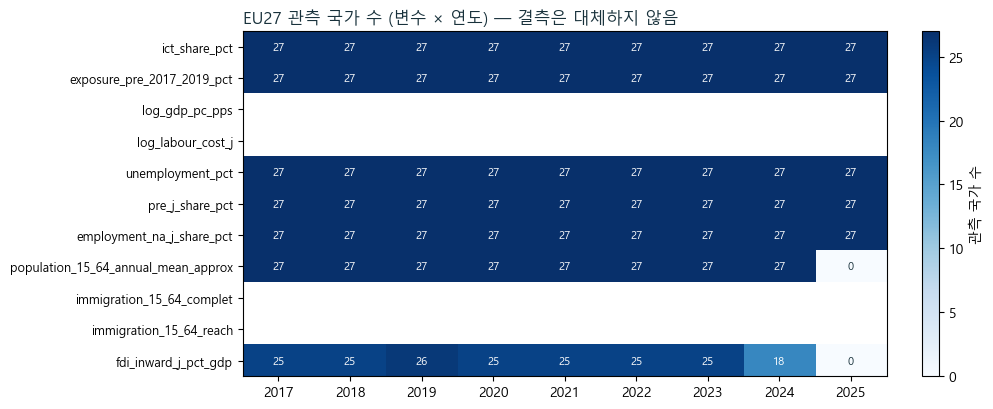

In [2]:
panel = read('combined_country_year.csv')
print(f"국가 {panel.country.nunique()}개 × 연도 {panel.year.nunique()}개 = {len(panel)}행, "
      f"EU27 표시 국가 {panel.loc[panel.sample_eu27==1,'country'].nunique()}개, 기간 {panel.year.min()}–{panel.year.max()}")
assert len(panel) == 288 and not panel.duplicated(['country', 'year']).any()

miss = read('combined_missingness.csv')
vars_ = ['ict_share_pct', 'exposure_pre_2017_2019_pct', 'log_gdp_pc_pps', 'log_labour_cost_j', 'unemployment_pct',
         'pre_j_share_pct', 'employment_na_j_share_pct', 'population_15_64_annual_mean_approx',
         'immigration_15_64_complet', 'immigration_15_64_reach', 'fdi_inward_j_pct_gdp']
tab = (miss[(miss.scope == 'EU27') & miss.variable.isin(vars_)]
       .pivot(index='variable', columns='year', values='observed').reindex(vars_))
display(tab)

fig, ax = plt.subplots(figsize=(10, 4.2))
im = ax.imshow(tab.to_numpy(dtype=float), cmap='Blues', vmin=0, vmax=27, aspect='auto')
ax.set_xticks(range(tab.shape[1])); ax.set_xticklabels(tab.columns)
ax.set_yticks(range(tab.shape[0])); ax.set_yticklabels(tab.index, fontsize=9)
for i in range(tab.shape[0]):
    for j in range(tab.shape[1]):
        v = tab.iat[i, j]
        if pd.notna(v): ax.text(j, i, int(v), ha='center', va='center', fontsize=8, color='white' if v > 14 else INK)
ax.set_title('EU27 관측 국가 수 (변수 × 연도) — 결측은 대체하지 않음', loc='left', color=INK)
fig.colorbar(im, ax=ax, fraction=0.025, label='관측 국가 수'); plt.tight_layout(); plt.show()

## 2. 분석 표본과 표준화

여섯 분석 묶음(`legacy`·`augmented`·`parsimonious`·`industry`·`migration`·`regional`)은 각각 `outputs/<group>/sample.csv`에 실제 회귀 표본을, `scaling.csv`에 설명변수의 표준화 기준(표본 평균·표준편차)을 저장합니다. 표준화 변수 `z_*`가 원변수에서 그대로 재현되는지 확인합니다. 표준화는 수치 안정성을 위한 것이며 VIF 등 진단값을 바꾸지 않습니다.

In [3]:
samples, scalings, weights = {}, {}, {}
rows = []
for g in GROUPS:
    s = read(f'{g}/sample.csv'); sc = read(f'{g}/scaling.csv'); w = read(f'{g}/weights.csv')
    assert s.id.tolist() == w.id.tolist() == list(w.columns[1:]), g   # 표본 순서 = W 행·열 순서
    maxdiff = max(abs((s[r.source] - r.center) / r.sd - s[r.term]).max() for r in sc.itertuples())
    samples[g], scalings[g], weights[g] = s, sc, w.set_index('id').to_numpy(dtype=float)
    rows.append(dict(group=g, n=len(s), outcome=read('all_model_comparisons.csv').query('group==@g').outcome.iloc[0],
                     z_vars=', '.join(sc.term), max_abs_diff_z=maxdiff))
overview = pd.DataFrame(rows).set_index('group'); display(overview)
assert (overview.max_abs_diff_z < 1e-9).all()

,n,outcome,z_vars,max_abs_diff_z
group,,,,
legacy,27,ict_share_pct,"z_exposure, z_income, z_cost, z_unemployment",2.0782e-13
augmented,27,ict_share_pct,"z_exposure, z_income, z_cost, z_unemployment, ...",2.0782e-13
parsimonious,27,ict_share_pct,"z_exposure, z_income, z_unemployment, z_pre_j",2.0782e-13
industry,27,employment_na_j_share_pct,"z_exposure, z_income, z_cost, z_unemployment",2.0782e-13
migration,20,asinh_immigration_15_64_complet_per1000,"z_exposure, z_income, z_unemployment",2.7600e-13
regional,218,regional_j_share_pct,"z_income, z_education",2.6090e-13


## 3. 공간가중치 W의 재구성

EPSG:3035 중심점 좌표(`x_m`, `y_m`)에서 k=4 최근접 이웃을 구하고, 관계를 **대칭 합집합**(A ∨ Aᵀ)으로 만든 뒤 행 표준화합니다. 대칭화 뒤 실제 이웃 수는 4보다 많을 수 있으며, 행 표준화 뒤의 W는 대칭이 아닙니다. 저장된 `weights.csv`와 원소 단위로 비교합니다.

,n,max_abs_diff_W,neighbours_min,neighbours_max,symmetric_W
group,,,,,
legacy,27,3.3307e-16,4,8,False
augmented,27,3.3307e-16,4,8,False
parsimonious,27,3.3307e-16,4,8,False
industry,27,3.3307e-16,4,8,False
migration,20,3.3307e-16,4,8,False
regional,218,3.3307e-16,4,9,False


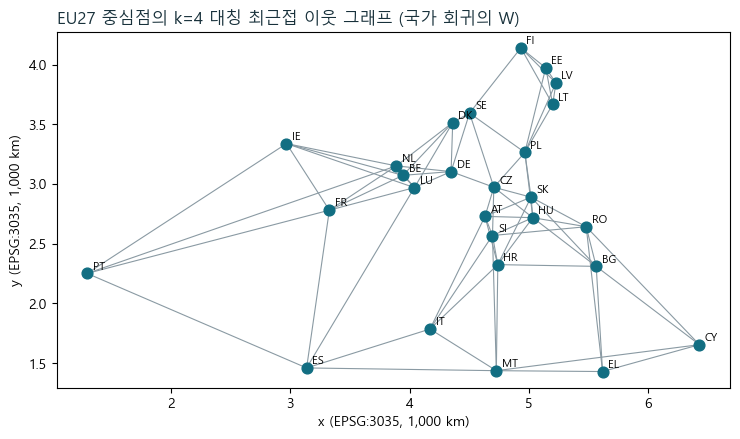

In [4]:
def knn_weights(xy, k=4):
    xy = np.asarray(xy, float)
    d = np.sqrt(((xy[:, None, :] - xy[None, :, :]) ** 2).sum(axis=2)); np.fill_diagonal(d, np.inf)
    A = np.zeros_like(d); idx = np.argsort(d, axis=1)[:, :k]
    A[np.arange(len(xy))[:, None], idx] = 1
    A = np.maximum(A, A.T)                       # 대칭 합집합 (spdep knn2nb(sym=TRUE))
    W = A / A.sum(axis=1, keepdims=True)         # 행 표준화 (style='W')
    assert np.allclose(W.sum(axis=1), 1) and (np.diag(W) == 0).all()
    return W, A

check_w = []
for g in GROUPS:
    s = samples[g]; W, A = knn_weights(s[['x_m', 'y_m']])
    check_w.append(dict(group=g, n=len(s), max_abs_diff_W=np.abs(W - weights[g]).max(),
                        neighbours_min=int(A.sum(1).min()), neighbours_max=int(A.sum(1).max()),
                        symmetric_W=bool(np.allclose(W, W.T))))
check_w = pd.DataFrame(check_w).set_index('group'); display(check_w)
assert (check_w.max_abs_diff_W < 1e-12).all()

# 국가 표본(EU27)의 이웃 그래프
s = samples['parsimonious']; W, A = knn_weights(s[['x_m', 'y_m']])
fig, ax = plt.subplots(figsize=(7.5, 6.5))
for i, j in zip(*np.where(np.triu(A) > 0)):
    ax.plot(s.x_m.iloc[[i, j]] / 1e6, s.y_m.iloc[[i, j]] / 1e6, color=GREY, lw=0.8, zorder=1)
ax.scatter(s.x_m / 1e6, s.y_m / 1e6, s=60, color=TEAL, zorder=2)
for r in s.itertuples(): ax.annotate(r.id, (r.x_m / 1e6, r.y_m / 1e6), xytext=(4, 3), textcoords='offset points', fontsize=8)
ax.set_xlabel('x (EPSG:3035, 1,000 km)'); ax.set_ylabel('y (EPSG:3035, 1,000 km)')
ax.set_title('EU27 중심점의 k=4 대칭 최근접 이웃 그래프 (국가 회귀의 W)', loc='left', color=INK)
ax.set_aspect('equal'); plt.tight_layout(); plt.show()

## 4. Moran's I와 순열 검정

전역 Moran's I = (n/S₀)·(zᵀWz)/(zᵀz), z는 평균 중심화한 결과변수입니다. R은 9,999회 무작위배치 순열로 p값을 구했습니다. 여기서는 I를 정확히 재현하고, 별도 난수열로 9,999회 순열을 다시 실행해 p값의 **통계적 일치**를 확인합니다(비트 단위 일치는 기대하지 않음). 큰 p는 공간 군집 부재의 증명이 아니며, 순열 검정은 W 선택에 조건부입니다.

,n,I_python,I_R,abs_diff_I,p_python,p_R
group,,,,,,
legacy,27,0.3000,0.3000,1.1102e-16,0.0074,0.0066
augmented,27,0.3000,0.3000,1.1102e-16,0.0074,0.0066
parsimonious,27,0.3000,0.3000,1.1102e-16,0.0074,0.0066
industry,27,0.0239,0.0239,5.5164e-16,0.5002,0.4908
migration,20,0.0587,0.0587,1.6029e-15,0.2740,0.2620
regional,218,0.0064,0.0064,9.5410e-18,0.7760,0.7728


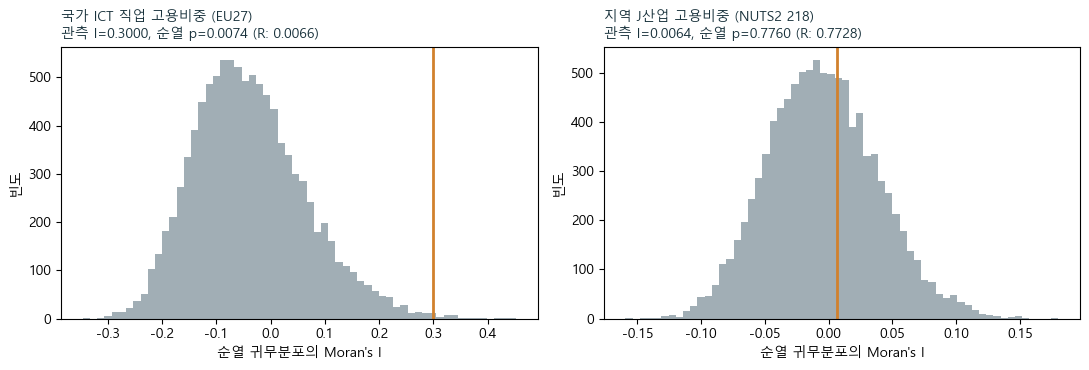

In [5]:
def moran_I(x, W):
    z = np.asarray(x, float) - np.mean(x); return len(z) / W.sum() * (z @ W @ z) / (z @ z)

def moran_permutation(x, W, B=9999, seed=20261103):
    rng = np.random.default_rng(seed); z = np.asarray(x, float) - np.mean(x); I = moran_I(x, W)
    perm = np.array([rng.permutation(z) for _ in range(B)])
    sims = len(z) / W.sum() * np.einsum('ij,ij->i', perm @ W.T, perm) / (z @ z)
    tail = min(np.sum(sims <= I), np.sum(sims >= I)); p = min(1, 2 * (tail + 1) / (B + 1))   # 양측
    return I, p, sims

moran_r = read('all_moran.csv')
rows, null_store = [], {}
for g in GROUPS:
    I, p, sims = moran_permutation(samples[g].outcome, weights[g]); null_store[g] = (I, sims)
    r = moran_r[(moran_r.group == g) & (moran_r.test == 'raw_permutation')].iloc[0]
    rows.append(dict(group=g, n=len(samples[g]), I_python=I, I_R=r.I, abs_diff_I=abs(I - r.I), p_python=p, p_R=r.p))
cmp_moran = pd.DataFrame(rows).set_index('group'); display(cmp_moran)
assert (cmp_moran.abs_diff_I < 1e-12).all()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, g, title in zip(axes, ['legacy', 'regional'], ['국가 ICT 직업 고용비중 (EU27)', '지역 J산업 고용비중 (NUTS2 218)']):
    I, sims = null_store[g]
    ax.hist(sims, bins=60, color=GREY, alpha=.8); ax.axvline(I, color=ORANGE, lw=2)
    ax.set_title(f"{title}\n관측 I={I:.4f}, 순열 p={cmp_moran.loc[g,'p_python']:.4f} (R: {cmp_moran.loc[g,'p_R']:.4f})", loc='left', fontsize=10, color=INK)
    ax.set_xlabel("순열 귀무분포의 Moran's I"); ax.set_ylabel('빈도')
plt.tight_layout(); plt.show()

## 5. 설계행렬과 VIF: X와 WX의 공선성

`design_matrix`는 R과 같은 규칙으로 설명변수 행렬을 만듭니다. `SDM_full`은 모든 X의 공간지연 WX를, `SDM_exposure`는 노출도(`z_exposure`)의 공간지연만 추가합니다. VIFⱼ = 1/(1−R²ⱼ)를 상수항 포함 보조회귀로 계산하고 `all_vif.csv`와 비교합니다. VIF는 X·WX의 선형 중복을 측정하며 Wy의 내생성이나 누락변수 문제를 다루지 않습니다.

VIF 135개 비교, 최대 절대 차이 9.95e-14


model,OLS,SDM_exposure,SDM_full
group,,,
augmented,3.55,4.10,43.29
industry,3.41,3.57,13.73
legacy,3.41,3.57,13.73
migration,1.24,3.14,4.59
parsimonious,2.13,3.18,5.89
regional,1.57,NaN,3.96


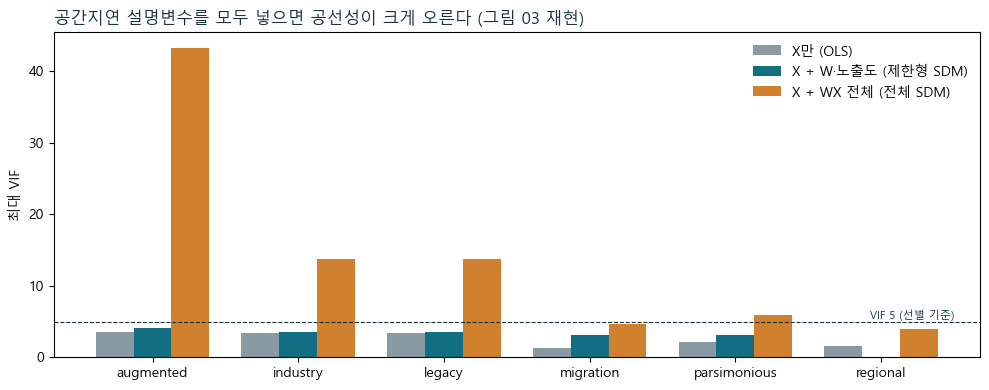

In [6]:
def design_matrix(g, model):
    s, zvars, W = samples[g], list(scalings[g].term), weights[g]
    Z = np.column_stack([np.ones(len(s))] + [s[v].to_numpy(float) for v in zvars]); labels = ['(Intercept)'] + zvars
    lags = zvars if model == 'SDM_full' else (['z_exposure'] if model == 'SDM_exposure' and 'z_exposure' in zvars else [])
    for v in lags: Z = np.column_stack([Z, W @ s[v].to_numpy(float)]); labels.append('lag.' + v)
    return Z, labels

def vif_values(Z, labels):
    out = {}
    for j in range(1, Z.shape[1]):
        y = Z[:, j]; X = np.delete(Z, j, axis=1)
        e = y - X @ np.linalg.lstsq(X, y, rcond=None)[0]
        out[labels[j]] = np.inf if e @ e < 1e-20 else ((y - y.mean()) ** 2).sum() / (e @ e)
    return out

vif_r = read('all_vif.csv'); rows = []
for g in GROUPS:
    for m in MODELS:
        if m == 'SDM_exposure' and 'z_exposure' not in list(scalings[g].term): continue   # 지역 모형에는 노출도 없음
        Z, labels = design_matrix(g, m)
        for term, v in vif_values(Z, labels).items():
            rv = vif_r[(vif_r.group == g) & (vif_r.model == m) & (vif_r.term == term)]
            if len(rv): rows.append(dict(group=g, model=m, term=term, VIF=v, VIF_R=float(rv.VIF.iloc[0])))
cmp_vif = pd.DataFrame(rows); cmp_vif['abs_diff'] = (cmp_vif.VIF - cmp_vif.VIF_R).abs()
print(f'VIF {len(cmp_vif)}개 비교, 최대 절대 차이 {cmp_vif.abs_diff.max():.2e}'); assert (cmp_vif.abs_diff < 1e-7).all()

maxvif = cmp_vif.groupby(['group', 'model']).VIF.max().unstack('model')[['OLS', 'SDM_exposure', 'SDM_full']]
display(maxvif.round(2))
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(maxvif)); w = 0.26
for i, (m, c) in enumerate([('OLS', GREY), ('SDM_exposure', TEAL), ('SDM_full', ORANGE)]):
    ax.bar(x + (i - 1) * w, maxvif[m].fillna(0), w, label={'OLS': 'X만 (OLS)', 'SDM_exposure': 'X + W·노출도 (제한형 SDM)', 'SDM_full': 'X + WX 전체 (전체 SDM)'}[m], color=c)
ax.axhline(5, ls='--', color=INK, lw=.8); ax.text(len(maxvif) - .5, 5.4, 'VIF 5 (선별 기준)', ha='right', fontsize=8, color=INK)
ax.set_xticks(x); ax.set_xticklabels(maxvif.index); ax.set_ylabel('최대 VIF'); ax.legend(frameon=False)
ax.set_title('공간지연 설명변수를 모두 넣으면 공선성이 크게 오른다 (그림 03 재현)', loc='left', color=INK); plt.tight_layout(); plt.show()

## 6. OLS·SAR·SEM·SDM 최대우도 추정

모형: SAR y = ρWy + Xβ + ε, SEM y = Xβ + u, u = λWu + ε, SDM y = ρWy + Xβ + WXθ + ε. 공간모수 하나에 대한 **집중 로그우도**

ℓ(a) = Σᵢ log(1 − a·evᵢ) − (n/2)[log 2π + 1 + log σ̂²(a)]

를 ρ∈(−0.999, 0.999)에서 격자 탐색 후 국소 최적화합니다(`fast_fit`과 동일: 격자 31점, 상위 3구간 brent). W의 고유값은 한 번만 계산합니다. 추정값·로그우도·AICc(= AIC + 2k(k+1)/(n−k−1), k는 σ²와 공간모수를 포함한 모수 수)를 `all_model_comparisons.csv`와 비교합니다. 공간모수가 −0.999 하한에 걸리는 모형(확장형 SEM·전체 SDM)은 R과 같이 경계 추정으로 표시합니다.

In [7]:
INTERVAL = (-0.999, 0.999)
eigen_cache = {g: np.linalg.eigvals(weights[g]) for g in GROUPS}
for g, ev in eigen_cache.items(): assert np.abs(ev.imag).max() < 1e-9, g
eigen_cache = {g: ev.real for g, ev in eigen_cache.items()}

def fit_model(y, Z, W, kind, ev):
    # kind: 'ols' | 'lag' (SAR/SDM) | 'error' (SEM). code/03_models.R fast_fit 과 동일한 집중 로그우도.
    n = len(y); wy = W @ y; wz = W @ Z
    if kind != 'error':
        b0 = np.linalg.lstsq(Z, y, rcond=None)[0]; b1 = np.linalg.lstsq(Z, wy, rcond=None)[0]
        e0, e1 = y - Z @ b0, wy - Z @ b1; q0, q1, q2 = e0 @ e0, e0 @ e1, e1 @ e1
    def evaluate(a, details=False):
        if kind == 'error':
            Za, ya = Z - a * wz, y - a * wy; b = np.linalg.lstsq(Za, ya, rcond=None)[0]; e = ya - Za @ b; s2 = e @ e / n
        else:
            s2 = (q0 - 2 * a * q1 + a * a * q2) / n
            if details: e, b = e0 - a * e1, b0 - a * b1
        if not np.isfinite(s2) or s2 <= 0: return -np.inf
        ll = (0 if kind == 'ols' else np.log(1 - a * ev).sum()) - n / 2 * (np.log(2 * np.pi) + 1 + np.log(s2))
        return dict(par=a, beta=b, innovation=e, s2=s2, ll=ll, kind=kind) if details else ll
    if kind == 'ols': return evaluate(0.0, True)
    grid = np.linspace(*INTERVAL, 31); score = np.array([evaluate(a) for a in grid])
    best = None
    for i in np.argsort(-score)[:3]:
        lo, hi = grid[max(0, i - 1)], grid[min(len(grid) - 1, i + 1)]
        r = minimize_scalar(lambda a: -evaluate(a), bounds=(lo, hi), method='bounded', options={'xatol': 1e-10})
        if best is None or -r.fun > best[1]: best = (r.x, -r.fun)
    return evaluate(best[0], True)

KIND = {'OLS': 'ols', 'SAR': 'lag', 'SEM': 'error', 'SDM_full': 'lag', 'SDM_exposure': 'lag'}
def fit(g, model):
    Z, labels = design_matrix(g, model); y = samples[g].outcome.to_numpy(float)
    res = fit_model(y, Z, weights[g], KIND[model], eigen_cache[g]); res['labels'] = labels; res['Z'] = Z
    res['innovation_I'] = moran_I(res['innovation'], weights[g]); return res

models_r = read('all_model_comparisons.csv'); fits, rows = {}, []
t0 = time.time()
for g in GROUPS:
    for m in MODELS:
        r = models_r[(models_r.group == g) & (models_r.model == m)]
        if not len(r): continue
        r = r.iloc[0]; f = fit(g, m); fits[(g, m)] = f
        n, k = len(samples[g]), int(r.parameters)
        aic = -2 * f['ll'] + 2 * k; aicc = aic + 2 * k * (k + 1) / (n - k - 1)
        rows.append(dict(group=g, model=m, n=n, logLik=f['ll'], logLik_R=r.logLik, dlogLik=abs(f['ll'] - r.logLik),
                         rho_or_lambda=f['par'], rho_R=r.spatial_parameter, drho=abs(f['par'] - r.spatial_parameter),
                         AICc=aicc, AICc_R=r.AICc, dAICc=abs(aicc - r.AICc), innovation_I=f['innovation_I'], dI=abs(f['innovation_I'] - r.innovation_I),
                         near_boundary=abs(f['par']) > 0.998))
cmp_models = pd.DataFrame(rows)
print(f'{len(cmp_models)}개 모형 재적합 {time.time()-t0:.1f}s; 최대 |ΔlogLik|={cmp_models.dlogLik.max():.2e}, 최대 |Δρ|={cmp_models.drho.max():.2e}, '
      f'최대 |ΔAICc|={cmp_models.dAICc.max():.2e}, 최대 |ΔI|={cmp_models.dI.max():.2e}')
display(cmp_models.set_index(['group', 'model'])[['n', 'logLik', 'logLik_R', 'rho_or_lambda', 'rho_R', 'AICc', 'AICc_R', 'innovation_I', 'near_boundary']])
assert (cmp_models.dlogLik < 1e-6).all() and (cmp_models.dAICc < 1e-5).all() and (cmp_models.drho < 1e-4).all()

29개 모형 재적합 0.3s; 최대 |ΔlogLik|=6.91e-08, 최대 |Δρ|=1.53e-07, 최대 |ΔAICc|=1.38e-07, 최대 |ΔI|=7.42e-08


n    logLik  logLik_R  rho_or_lambda   rho_R      AICc    AICc_R  innovation_I  near_boundary
group        model                                                                                                        
legacy       OLS            27  -38.0322  -38.0322         0.0000  0.0000   92.2644   92.2644        0.1288          False
             SAR            27  -37.5787  -37.5787         0.2208  0.2208   95.0522   95.0522        0.0203          False
             SEM            27  -37.3582  -37.3582         0.3458  0.3458   94.6111   94.6111       -0.0261          False
             SDM_full       27  -28.4683  -28.4683        -0.6446 -0.6446   96.5366   96.5366       -0.1761          False
             SDM_exposure   27  -36.7934  -36.7934         0.3394  0.3394   97.5868   97.5868       -0.0309          False
augmented    OLS            27  -33.4752  -33.4752         0.0000  0.0000   86.8451   86.8451       -0.0920          False
             SAR            27  -33.1833  -33.1833         0.1589  0.1589   90.3665   90.3665       -0.1633          False
             SEM            27  -30.6543  -30.6543        -0.9990 -0.9990   85.3085   85.3085       -0.0995           True
             SDM_full       27  -20.1150  -20.1150        -0.9990 -0.9990   94.2300   94.2300       -0.1570           True
             SDM_exposure   27  -33.0743  -33.0743         0.2078  0.2078   94.7369   94.7369       -0.1761          False
parsimonious OLS            27  -35.3166  -35.3166         0.0000  0.0000   86.8331   86.8331        0.0346          False
             SAR            27  -34.3647  -34.3647         0.2747  0.2747   88.6242   88.6242       -0.1257          False
             SEM            27  -35.2428  -35.2428         0.1493  0.1493   90.3803   90.3803       -0.0090          False
             SDM_full       27  -26.9337  -26.9337        -0.8135 -0.8135   93.4674   93.4674       -0.0850          False
             SDM_exposure   27  -34.3167  -34.3167         0.3081  0.3081   92.6335   92.6335       -0.1336          False
industry     OLS            27  -35.3613  -35.3613         0.0000  0.0000   86.9225   86.9225        0.1671          False
             SAR            27  -35.0718  -35.0718         0.2399  0.2399   90.0382   90.0382        0.0865          False
             SEM            27  -33.9113  -33.9113         0.5334  0.5334   87.7173   87.7173       -0.0118          False
             SDM_full       27  -28.7151  -28.7151        -0.0750 -0.0750   97.0301   97.0301       -0.1324          False
             SDM_exposure   27  -32.2304  -32.2304         0.3650  0.3650   88.4609   88.4609        0.0866          False
migration    OLS            20  -21.1034  -21.1034         0.0000  0.0000   56.4925   56.4925       -0.0624          False
             SAR            20  -20.9677  -20.9677        -0.1918 -0.1918   60.3969   60.3969       -0.0056          False
             SEM            20  -20.9727  -20.9727        -0.2103 -0.2103   60.4069   60.4069       -0.0002          False
             SDM_full       20  -18.9242  -18.9242        -0.0809 -0.0809   73.8485   73.8485        0.0186          False
             SDM_exposure   20  -20.8054  -20.8054        -0.1388 -0.1388   64.9441   64.9441       -0.0161          False
regional     OLS           218 -388.4980 -388.4980         0.0000  0.0000  785.1839  785.1839        0.2768          False
             SAR           218 -388.3036 -388.3036        -0.0513 -0.0513  786.8901  786.8901        0.2984          False
             SEM           218 -361.5805 -361.5805         0.6343  0.6343  733.4440  733.4440       -0.0463          False
             SDM_full      218 -345.6409 -345.6409         0.4045  0.4045  705.8151  705.8151       -0.0269          False

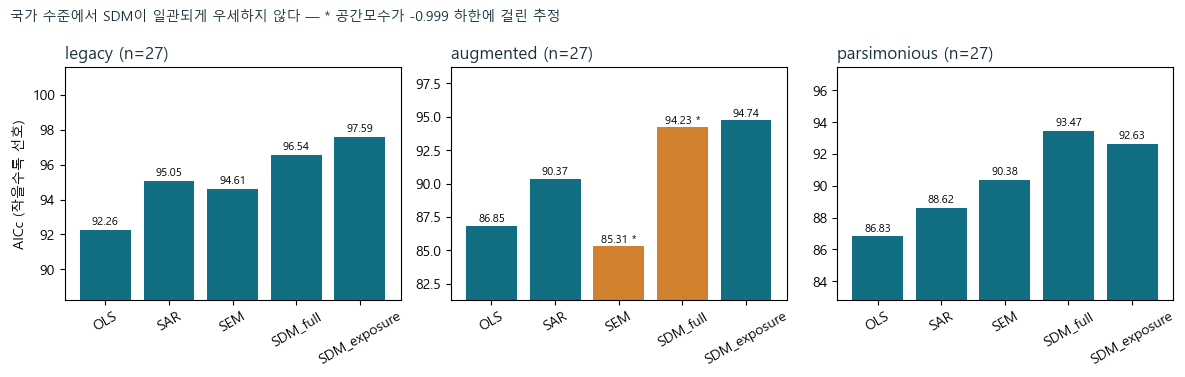

In [8]:
# 동일 표본·결과변수 안에서만 AICc를 비교한다 (그림 04 재현: 국가 ICT 고용비중 세 구성)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=False)
for ax, g in zip(axes, ['legacy', 'augmented', 'parsimonious']):
    d = cmp_models[cmp_models.group == g].set_index('model').reindex(MODELS)
    colors = [ORANGE if b else TEAL for b in d.near_boundary]
    ax.bar(d.index, d.AICc, color=colors)
    for i, (v, b) in enumerate(zip(d.AICc, d.near_boundary)): ax.text(i, v + .3, f'{v:.2f}' + (' *' if b else ''), ha='center', fontsize=8)
    ax.set_title(f'{g} (n={int(d.n.iloc[0])})', loc='left', color=INK); ax.set_ylim(d.AICc.min() - 4, d.AICc.max() + 4)
    ax.tick_params(axis='x', rotation=30)
axes[0].set_ylabel('AICc (작을수록 선호)')
fig.suptitle('국가 수준에서 SDM이 일관되게 우세하지 않다 — * 공간모수가 -0.999 하한에 걸린 추정', x=0.01, ha='left', fontsize=10, color=INK)
plt.tight_layout(); plt.show()

## 7. 효과 분해: 직접·간접·총효과

SAR·SDM에서는 설명변수 k의 변화가 공간승수 S_k(W) = (I − ρW)⁻¹(Iβ_k + Wθ_k)를 통해 모든 지역에 퍼집니다. 직접효과 = S_k의 대각 평균, 총효과 = 행합 평균 = (β_k + θ_k)/(1 − ρ)(W가 행 표준화이므로), 간접효과 = 총 − 직접. 고유값 trace 공식으로 역행렬 없이 계산합니다.

저장된 `all_impacts.csv`는 **원척도**(노출도 1%p당 결과변수 %p)이므로 표준화 효과를 해당 변수의 표본 표준편차로 나눠 비교합니다. 구간은 R에서 모수적 부트스트랩(모형 재적합 999회)으로 구했습니다. 여기서는 간결형(parsimonious) 제한형 SDM에 대해 같은 절차를 다른 난수열로 반복해 구간의 폭이 비슷한지 확인합니다. 효과 분해는 조건부 연관성의 분해이며, 간접효과를 규범 확산의 증거로 읽지 않습니다.

In [9]:
def impacts(f, ev, zvars):
    a = f['par'] if f['kind'] == 'lag' else 0.0
    trS, trSW = np.mean(1 / (1 - a * ev)), np.mean(ev / (1 - a * ev)); out = {}
    for v in zvars:
        beta = f['beta'][f['labels'].index(v)]
        theta = f['beta'][f['labels'].index('lag.' + v)] if 'lag.' + v in f['labels'] else 0.0
        direct = trS * beta + trSW * theta; total = (beta + theta) / (1 - a)
        out[v] = dict(direct=direct, indirect=total - direct, total=total)
    return out

imp_r = read('all_impacts.csv'); rows = []
for g in ['legacy', 'augmented', 'parsimonious', 'industry', 'migration']:
    for m in ['SAR', 'SDM_full', 'SDM_exposure']:
        sd = scalings[g].set_index('term').sd
        for v, eff in impacts(fits[(g, m)], eigen_cache[g], list(scalings[g].term)).items():
            for kind, val in eff.items():
                r = imp_r[(imp_r.group == g) & (imp_r.model == m) & (imp_r.term == v) & (imp_r.effect == kind)]
                if len(r): rows.append(dict(group=g, model=m, term=v, effect=kind, estimate=val / sd[v], estimate_R=float(r.estimate.iloc[0]), lower_R=float(r.lower.iloc[0]), upper_R=float(r.upper.iloc[0])))
cmp_imp = pd.DataFrame(rows); cmp_imp['abs_diff'] = (cmp_imp.estimate - cmp_imp.estimate_R).abs()
print(f'효과 {len(cmp_imp)}개 비교, 최대 절대 차이 {cmp_imp.abs_diff.max():.2e}'); assert (cmp_imp.abs_diff < 1e-6).all()
display(cmp_imp[(cmp_imp.model == 'SDM_exposure') & (cmp_imp.term == 'z_exposure')].set_index(['group', 'effect'])[['estimate', 'estimate_R', 'lower_R', 'upper_R']])

효과 180개 비교, 최대 절대 차이 1.25e-07


estimate  estimate_R  lower_R  upper_R
group        effect                                          
legacy       direct     -0.2687     -0.2687  -0.4717  -0.0126
             indirect   -0.5399     -0.5399  -1.5357   0.2929
             total      -0.8087     -0.8087  -1.9721   0.1874
augmented    direct     -0.1079     -0.1079  -0.3113   0.1272
             indirect   -0.1495     -0.1495  -0.7700   0.3813
             total      -0.2574     -0.2574  -1.0056   0.4331
parsimonious direct     -0.0518     -0.0518  -0.2504   0.1735
             indirect   -0.1147     -0.1147  -0.7861   0.4682
             total      -0.1665     -0.1665  -0.9321   0.5565
industry     direct     -0.1371     -0.1371  -0.3116   0.0826
             indirect   -0.7344     -0.7344  -1.4556  -0.0333
             total      -0.8716     -0.8716  -1.7235  -0.0336
migration    direct     -0.0098     -0.0098  -0.1446   0.1444
             indirect   -0.1172     -0.1172  -0.5188   0.2760
             total      -0.1269     -0.1269  -0.5791   0.2983

B=999 재적합 부트스트랩 5.4s (난수열은 R과 다름)


,lower_python,upper_python,estimate,lower_R,upper_R
effect,,,,,
direct,-0.2516,0.1730,-0.0518,-0.2504,0.1735
indirect,-0.7469,0.4329,-0.1147,-0.7861,0.4682
total,-0.8961,0.5536,-0.1665,-0.9321,0.5565


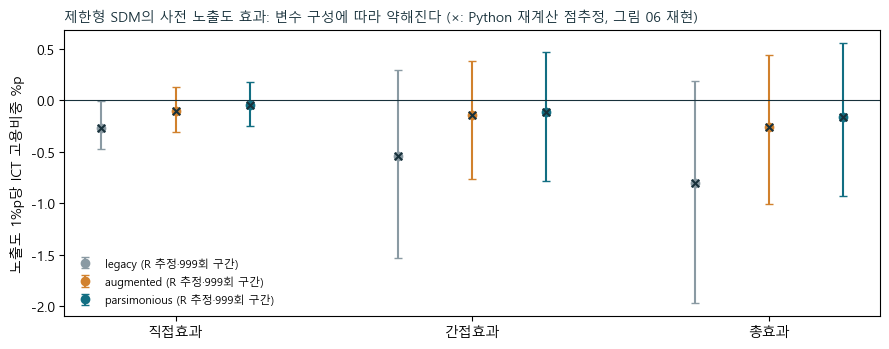

In [10]:
def parametric_bootstrap_impacts(g, model, term, B=999, seed=20261103):
    f = fits[(g, model)]; W, ev = weights[g], eigen_cache[g]; Z = f['Z']; n = len(Z)
    rng = np.random.default_rng(seed); a = f['par']
    Ainv = np.linalg.inv(np.eye(n) - a * W) if f['kind'] == 'lag' else None
    mu = Z @ f['beta']; sd = scalings[g].set_index('term').sd[term]; draws = []
    for _ in range(B):
        eps = rng.normal(0, np.sqrt(f['s2']), n)
        y_star = Ainv @ (mu + eps) if f['kind'] == 'lag' else mu + eps
        fb = fit_model(y_star, Z, W, f['kind'], ev); fb['labels'] = f['labels']
        e = impacts(fb, ev, [term])[term]; draws.append([e['direct'] / sd, e['indirect'] / sd, e['total'] / sd])
    return np.array(draws)

t0 = time.time(); draws = parametric_bootstrap_impacts('parsimonious', 'SDM_exposure', 'z_exposure')
q = np.percentile(draws, [2.5, 97.5], axis=0)
boot = pd.DataFrame({'effect': ['direct', 'indirect', 'total'], 'lower_python': q[0], 'upper_python': q[1]}).set_index('effect')
ref = cmp_imp[(cmp_imp.group == 'parsimonious') & (cmp_imp.model == 'SDM_exposure') & (cmp_imp.term == 'z_exposure')].set_index('effect')
boot = boot.join(ref[['estimate', 'lower_R', 'upper_R']]); print(f'B=999 재적합 부트스트랩 {time.time()-t0:.1f}s (난수열은 R과 다름)'); display(boot)

fig, ax = plt.subplots(figsize=(9, 3.6))
groups = ['legacy', 'augmented', 'parsimonious']; eff = ['direct', 'indirect', 'total']; x = np.arange(len(eff)); w = .25
for i, (g, c) in enumerate(zip(groups, [GREY, ORANGE, TEAL])):
    d = cmp_imp[(cmp_imp.group == g) & (cmp_imp.model == 'SDM_exposure') & (cmp_imp.term == 'z_exposure')].set_index('effect').reindex(eff)
    ax.errorbar(x + (i - 1) * w, d.estimate_R, yerr=[d.estimate_R - d.lower_R, d.upper_R - d.estimate_R], fmt='o', color=c, capsize=3, label=f'{g} (R 추정·999회 구간)')
    ax.scatter(x + (i - 1) * w, d.estimate, marker='x', color=INK, zorder=3, s=30)
ax.axhline(0, color=INK, lw=.8); ax.set_xticks(x); ax.set_xticklabels(['직접효과', '간접효과', '총효과'])
ax.set_ylabel('노출도 1%p당 ICT 고용비중 %p'); ax.legend(frameon=False, fontsize=8)
ax.set_title('제한형 SDM의 사전 노출도 효과: 변수 구성에 따라 약해진다 (×: Python 재계산 점추정, 그림 06 재현)', loc='left', fontsize=10, color=INK)
plt.tight_layout(); plt.show()

## 8. 지역 SDM 잔차의 모수적 부트스트랩 검정

지역(NUTS2, n=218) 전체 SDM의 혁신잔차 ε̂ = y − ρ̂Wy − Xβ̂ − WXθ̂에 공간자기상관이 남아 있는지를 검정합니다. 적합 모형에서 정규 혁신오차를 생성해 y* = (I − ρ̂W)⁻¹(Xβ̂ + WXθ̂ + ε*)를 만들고 **매회 SDM을 재적합**한 뒤 잔차 I의 분포를 구합니다(잔차의 단순 재배열과 다름). 양측 p = min[1, 2(작은 꼬리 횟수 + 1)/(B + 1)].

R 결과는 B=199에서 p=0.0700, B=9,999에서 p=0.0526이며 몬테카를로 구간이 0.05를 가로지릅니다. 여기서는 B=1,999를 다른 난수열로 실행해 같은 범위에 들어오는지 확인하고, 저장된 반복 수별 결과(`regional_sdm_bootstrap_comparison.csv`)를 그립니다. 반복 증가는 모의실험 오차를 줄일 뿐 정책효과의 증거를 만들지 않습니다.

지역 SDM 잔차 I=-0.02689; Python B=1999: p=0.0620, 경계 비율 0.000 (14.2s)
R: B=199 p=0.0700 [0.0223, 0.1289], B=999 p=0.0580 [0.0374, 0.0805], B=1999 p=0.0600 [0.0451, 0.0758], B=4999 p=0.0536 [0.0446, 0.0629], B=9999 p=0.0526 [0.0463, 0.0590]


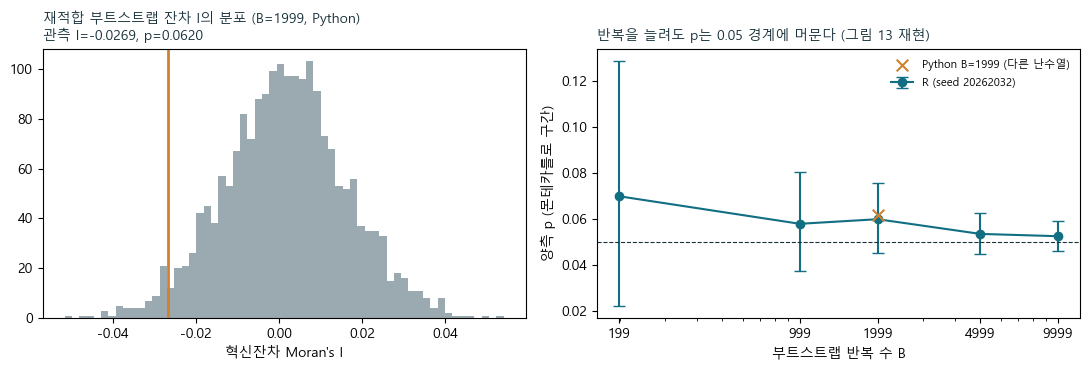

In [11]:
def residual_bootstrap(g, model, B=1999, seed=20261103):
    f = fits[(g, model)]; W, ev, Z = weights[g], eigen_cache[g], f['Z']; n = len(Z)
    rng = np.random.default_rng(seed); a = f['par']; mu = Z @ f['beta']
    Ainv = np.linalg.inv(np.eye(n) - a * W) if f['kind'] == 'lag' else None
    sims, pars = np.empty(B), np.empty(B)
    for b in range(B):
        eps = rng.normal(0, np.sqrt(f['s2']), n); y_star = Ainv @ (mu + eps) if Ainv is not None else mu + eps
        fb = fit_model(y_star, Z, W, f['kind'], ev); sims[b] = moran_I(fb['innovation'], W); pars[b] = fb['par']
    I = f['innovation_I']; tail = min(np.sum(sims <= I), np.sum(sims >= I))
    return dict(I=I, p=min(1, 2 * (tail + 1) / (B + 1)), B=B, sims=sims, boundary_fraction=float(np.mean(np.abs(pars) > 0.998)))

t0 = time.time(); rb = residual_bootstrap('regional', 'SDM_full')
comp = read('regional_sdm_bootstrap_comparison.csv')
print(f"지역 SDM 잔차 I={rb['I']:.5f}; Python B={rb['B']}: p={rb['p']:.4f}, 경계 비율 {rb['boundary_fraction']:.3f} ({time.time()-t0:.1f}s)")
print('R:', ', '.join(f'B={int(r.simulations)} p={r.p_bootstrap:.4f} [{r.MC_lower:.4f}, {r.MC_upper:.4f}]' for r in comp.itertuples()))
assert abs(rb['I'] - comp.I.iloc[0]) < 1e-6   # ρ̂ 최적화 허용오차 수준에서 일치

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]; ax.hist(rb['sims'], bins=60, color=GREY, alpha=.85); ax.axvline(rb['I'], color=ORANGE, lw=2)
ax.set_title(f"재적합 부트스트랩 잔차 I의 분포 (B={rb['B']}, Python)\n관측 I={rb['I']:.4f}, p={rb['p']:.4f}", loc='left', fontsize=10, color=INK); ax.set_xlabel("혁신잔차 Moran's I")
ax = axes[1]; ax.errorbar(comp.simulations, comp.p_bootstrap, yerr=[comp.p_bootstrap - comp.MC_lower, comp.MC_upper - comp.p_bootstrap], fmt='o-', color=TEAL, capsize=4, label='R (seed 20262032)')
ax.scatter([rb['B']], [rb['p']], marker='x', color=ORANGE, s=70, zorder=3, label=f'Python B={rb["B"]} (다른 난수열)')
ax.axhline(.05, ls='--', color=INK, lw=.8); ax.set_xscale('log'); ax.set_xticks(comp.simulations); ax.set_xticklabels(comp.simulations.astype(int))
ax.set_xlabel('부트스트랩 반복 수 B'); ax.set_ylabel('양측 p (몬테카를로 구간)'); ax.legend(frameon=False, fontsize=8)
ax.set_title('반복을 늘려도 p는 0.05 경계에 머문다 (그림 13 재현)', loc='left', fontsize=10, color=INK); plt.tight_layout(); plt.show()

## 9. 이웃 수 k에 대한 민감도

저장된 `k_sensitivity.csv`(k=3·4·5, 각 k에서 W를 재구성해 재적합)를 읽어 분석 묶음별 ΔAICc(해당 k 안에서 최소 AICc 대비)를 비교합니다. 지역 SDM의 우위는 k에 걸쳐 유지되지만 국가 모형의 순위는 k에 따라 바뀝니다. 아래에서 k=4의 값이 6절의 재적합과 일치하는지도 확인합니다.

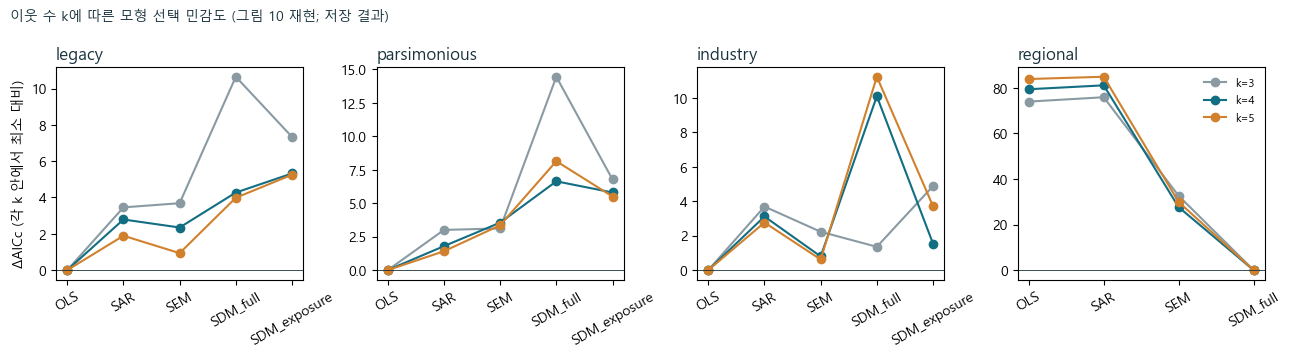

k,3,4,5
model,,,
OLS,785.18,785.18,785.18
SAR,787.10,786.89,786.18
SDM_full,711.24,705.82,701.33
SEM,743.83,733.44,731.21


In [12]:
ks = pd.concat([read(f'{g}/k_sensitivity.csv') for g in GROUPS], ignore_index=True)
k4 = ks[ks.k == 4].merge(cmp_models[['group', 'model', 'AICc']], on=['group', 'model'], suffixes=('_file', '_refit'))
assert (k4.AICc_file - k4.AICc_refit).abs().max() < 1e-5

fig, axes = plt.subplots(1, 4, figsize=(13, 3.6), sharey=False)
for ax, g in zip(axes, ['legacy', 'parsimonious', 'industry', 'regional']):
    d = ks[ks.group == g].pivot(index='model', columns='k', values='delta_AICc').reindex([m for m in MODELS if m in set(ks[ks.group == g].model)])
    for k, c in zip([3, 4, 5], [GREY, TEAL, ORANGE]): ax.plot(d.index, d[k], 'o-', color=c, label=f'k={k}')
    ax.set_title(g, loc='left', color=INK); ax.tick_params(axis='x', rotation=30); ax.axhline(0, color=INK, lw=.6)
axes[0].set_ylabel('ΔAICc (각 k 안에서 최소 대비)'); axes[-1].legend(frameon=False, fontsize=8)
fig.suptitle('이웃 수 k에 따른 모형 선택 민감도 (그림 10 재현; 저장 결과)', x=0.01, ha='left', fontsize=10, color=INK); plt.tight_layout(); plt.show()
display(ks[ks.group == 'regional'].pivot(index='model', columns='k', values='AICc').round(2))

## 10. 2026-11-02 메커니즘 자료: 준수 변경·기업 사건·국가쌍 흐름

브뤼셀 효과(규범 확산)와 티부형 이동은 관측 단위가 다릅니다. 추가 수집 자료는 세 층으로 나뉘며 회귀에 편입하지 않았습니다: (1) 게이트키퍼 준수 변경의 지리적 적용범위, (2) 공개된 기업 이전·재편 사건, (3) Eurostat 국가쌍 이민·FDI·외국계 기업 패널. 기준 흐름 자료는 `outputs/mechanisms_20261102/flows/fresh/`입니다. 행 수는 연령·방향·산업·단위 차원을 포함한 셀 수이며 이동 사건 수가 아닙니다.

,domain,path,rows,year_min,year_max
0,compliance,inputs/mechanisms_20261102/compliance/csv/comp...,13,NaN,NaN
1,compliance,inputs/mechanisms_20261102/compliance/metadata...,18,NaN,NaN
2,compliance,inputs/mechanisms_20261102/compliance/SOURCE_M...,9,NaN,NaN
3,firms,inputs/mechanisms_20261102/firms/csv/access_re...,3,NaN,NaN
4,firms,inputs/mechanisms_20261102/firms/csv/firm_even...,17,2017.0,2026.0
...,...,...,...,...,...
67,flows,outputs/mechanisms_20261102/flows/mirror_summa...,2,NaN,NaN
68,flows,outputs/mechanisms_20261102/flows/native_dupli...,0,NaN,NaN
69,flows,outputs/mechanisms_20261102/flows/snapshot_sco...,5,NaN,NaN
70,flows,outputs/mechanisms_20261102/flows/SOURCE_MANIF...,6,NaN,NaN


준수 기록 13개 (변경 12 + 현재 스냅샷 1), 기업 사건 11건, 국가쌍 셀 205,784행 중 수치 관측 85,278행 (41.4%)


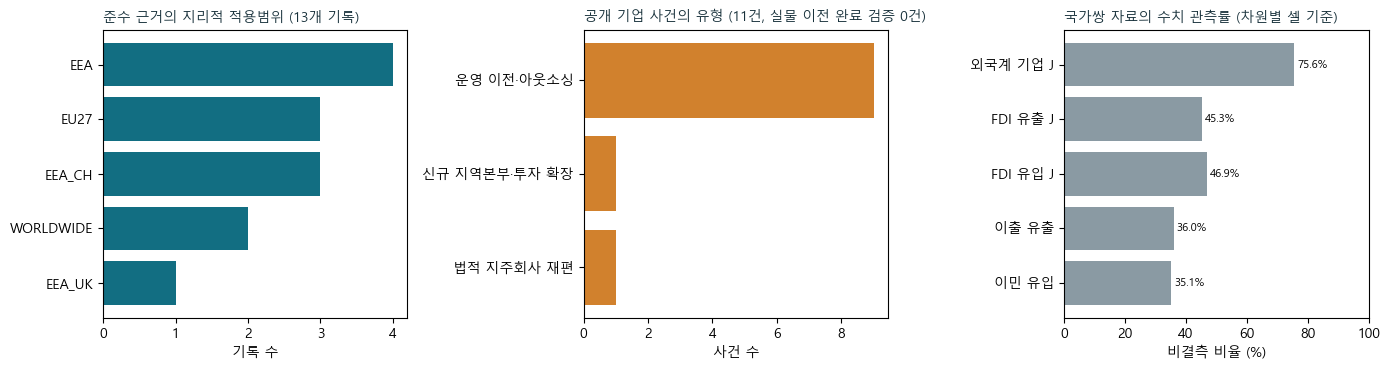

In [13]:
mech = OUT / 'mechanisms_20261102'
catalog = pd.read_csv(mech / 'integration/integration_catalog.csv'); display(catalog[['domain', 'path', 'rows', 'year_min', 'year_max']])
scope = pd.read_csv(mech / 'integration/figure_compliance_scope.csv'); cases = pd.read_csv(mech / 'integration/figure_firm_case_types.csv').sort_values('count')
cov = pd.read_csv(mech / 'integration/figure_flow_coverage.csv')
print(f"준수 기록 {int(scope['count'].sum())}개 (변경 {int(scope.loc[scope.record_kind=='change','count'].sum())} + 현재 스냅샷 {int(scope.loc[scope.record_kind!='change','count'].sum())}), "
      f"기업 사건 {int(cases['count'].sum())}건, 국가쌍 셀 {int(cov.rows.sum()):,}행 중 수치 관측 {int(cov.observed.sum()):,}행 ({cov.observed.sum()/cov.rows.sum():.1%})")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
sc = scope.groupby('geographic_scope_code')['count'].sum().sort_values()
axes[0].barh(sc.index, sc.values, color=TEAL); axes[0].set_title('준수 근거의 지리적 적용범위 (13개 기록)', loc='left', fontsize=10, color=INK); axes[0].set_xlabel('기록 수')
axes[1].barh(cases.label, cases['count'], color=ORANGE); axes[1].set_title('공개 기업 사건의 유형 (11건, 실물 이전 완료 검증 0건)', loc='left', fontsize=10, color=INK); axes[1].set_xlabel('사건 수')
axes[2].barh(cov.label, cov.observed_pct, color=GREY)
for i, v in enumerate(cov.observed_pct): axes[2].text(v + 1, i, f'{v:.1f}%', va='center', fontsize=8)
axes[2].set_xlim(0, 100); axes[2].set_title('국가쌍 자료의 수치 관측률 (차원별 셀 기준)', loc='left', fontsize=10, color=INK); axes[2].set_xlabel('비결측 비율 (%)')
plt.tight_layout(); plt.show()

year,2017,2018,2019,2020,2021,2022,2023,2024
source_id,,,,,,,,
fdi_inward_j,46.1,45.6,47.0,51.6,53.4,52.9,47.5,31.2
fdi_outward_j,44.7,43.7,45.7,49.2,51.5,50.5,46.1,30.6
foreign_affiliates_j,NaN,NaN,NaN,NaN,74.9,74.8,76.9,75.7
migration_inward,36.4,36.9,35.3,37.2,37.3,32.6,32.0,32.8
migration_outward,40.3,38.4,39.7,37.0,34.8,32.3,32.3,33.0


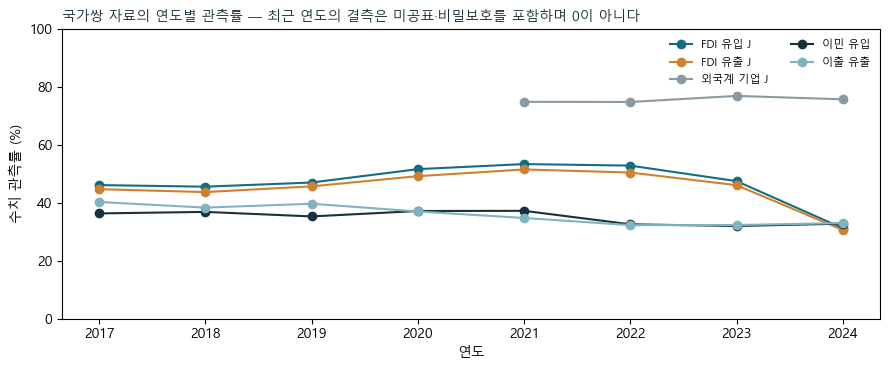

In [14]:
# 국가쌍 흐름의 연도별 수치 관측률 — 기준 자료(flows/fresh). 차원(연령·산업·지표)을 합산한 셀 기준.
flows = pd.read_csv(mech / 'flows/fresh/coverage_by_year_dimension.csv')
byyear = flows.groupby(['source_id', 'year'])[['rows', 'observed']].sum().reset_index()
byyear['observed_pct'] = 100 * byyear.observed / byyear.rows
display(byyear.pivot(index='source_id', columns='year', values='observed_pct').round(1))

fig, ax = plt.subplots(figsize=(9, 3.8))
labels = dict(zip(cov.source_id, cov.label))
for (sid, d), c in zip(byyear.groupby('source_id'), [TEAL, ORANGE, GREY, INK, '#7fb3c0']):
    ax.plot(d.year, d.observed_pct, 'o-', color=c, label=labels.get(sid, sid))
ax.set_ylim(0, 100); ax.set_ylabel('수치 관측률 (%)'); ax.set_xlabel('연도'); ax.legend(frameon=False, fontsize=8, ncol=2)
ax.set_title('국가쌍 자료의 연도별 관측률 — 최근 연도의 결측은 미공표·비밀보호를 포함하며 0이 아니다', loc='left', fontsize=10, color=INK)
plt.tight_layout(); plt.show()

## 11. 요약

| 단계 | Python 재계산 | R 저장 결과와의 일치 |
|---|---|---|
| 표본·표준화 | z = (x − 평균)/표준편차 | 6개 묶음 모두 1e-9 이내 |
| 공간가중치 W | k=4 대칭 kNN, 행 표준화 | 원소 단위 1e-12 이내 |
| Moran's I | 통계량 정확 재현, 순열 9,999회 | I 일치, p는 통계적으로 일치 |
| VIF | X·WX 설계행렬의 보조회귀 | 1e-7 이내 |
| ML 추정 | 집중 로그우도, 격자 + brent | logLik 1e-6, AICc 1e-5 이내 |
| 효과 분해 | trace 공식, 원척도 환산 | 점추정 1e-6 이내, 부트스트랩 구간 폭 유사 |
| 지역 SDM 잔차 검정 | 재적합 부트스트랩 B=1,999 | p가 R의 MC 구간과 같은 범위 |

**해석의 한계는 그대로입니다.** 재현된 수치는 2024년 단면의 조건부 연관성과 모형 진단이며, 노출도 변수는 DMA 처치량이 아니고 공간 간접효과는 규범 확산의 관측치가 아닙니다. 지역 SDM의 잔차 p는 0.05 경계에 있어 "공간의존성을 제거했다"고 말하지 않습니다. 기업·투자·인력 이동을 검증하려면 10절의 자료층을 출발지–목적지–시점 단위로 확장해야 합니다(`reports/DMA_Mechanisms_Research_Design_20261102.md`).